In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q torch_geometric
!pip install -q class_resolver
!pip3 install pymatting

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.2 MB/s eta 0:00:00


In [ ]:
import os
import copy
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as nnF
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import ARMAConv

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_auc_score

/home/snu/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:
# === Load Patients ===
fa_patients_path = "/home/snu/Downloads/NIFD_Patients_FA_Histogram_Feature.npy"
Patients_FA_array = np.load(fa_patients_path, allow_pickle=True)

# === Load Controls ===
fa_controls_path = "/home/snu/Downloads/NIFD_Control_FA_Histogram_Feature.npy"
Controls_FA_array = np.load(fa_controls_path, allow_pickle=True)

print("Patients Shape:", Patients_FA_array.shape)
print("Controls Shape:", Controls_FA_array.shape)

# === Combine features and labels ===
X = np.vstack([Controls_FA_array, Patients_FA_array])
y = np.hstack([
    np.zeros(Controls_FA_array.shape[0], dtype=np.int64),  # 0 = Control
    np.ones(Patients_FA_array.shape[0], dtype=np.int64)    # 1 = Patient
])

# Shuffle
np.random.seed(42)
perm = np.random.permutation(X.shape[0])
X = X[perm]
y = y[perm]
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Patients Shape: (98, 180)
Controls Shape: (48, 180)
X Shape: (146, 180)
y Shape: (146,)


Image shape: (100, 100, 60, 120)


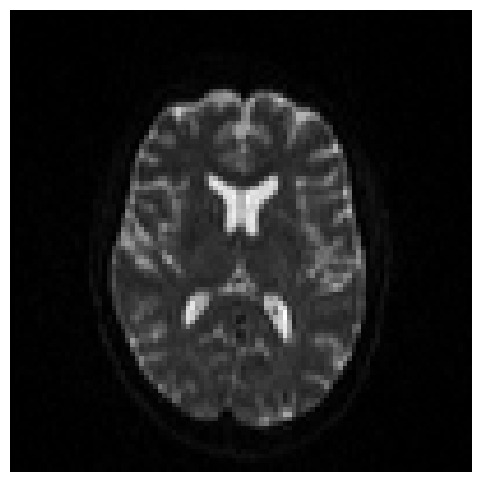

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

# Load NIfTI image
nii_path = "/home/snu/Downloads/4d_img_DTI_4d_img_1_S_0228_Controls.nii.gz"

nii_img = nib.load(nii_path)

data = nii_img.get_fdata()

print("Image shape:", data.shape)

# Take middle slice
if data.ndim == 4:
    slice_img = data[:, :, data.shape[2] // 2, 0]
else:
    slice_img = data[:, :, data.shape[2] // 2]

# Rotate for proper orientation
slice_img = np.rot90(slice_img)

# Plot
plt.figure(figsize=(6,6))
plt.imshow(slice_img, cmap="gray", interpolation="nearest")
plt.axis("off")
plt.show()

Image shape: (116, 116, 80, 55)


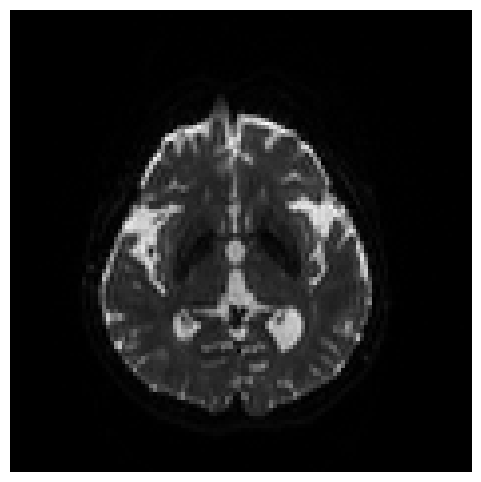

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

# Load NIfTI image
nii_path = "/home/snu/Downloads/4d_img_DTI_033_S_10016_F_73_MCI (1).nii.gz"

nii_img = nib.load(nii_path)

data = nii_img.get_fdata()

print("Image shape:", data.shape)

# Take middle slice
if data.ndim == 4:
    slice_img = data[:, :, data.shape[2] // 2, 0]
else:
    slice_img = data[:, :, data.shape[2] // 2]

# Rotate for proper orientation
slice_img = np.rot90(slice_img)

# Plot
plt.figure(figsize=(6,6))
plt.imshow(slice_img, cmap="gray", interpolation="nearest")
plt.axis("off")
plt.show()

Image shape: (116, 116, 80, 55)


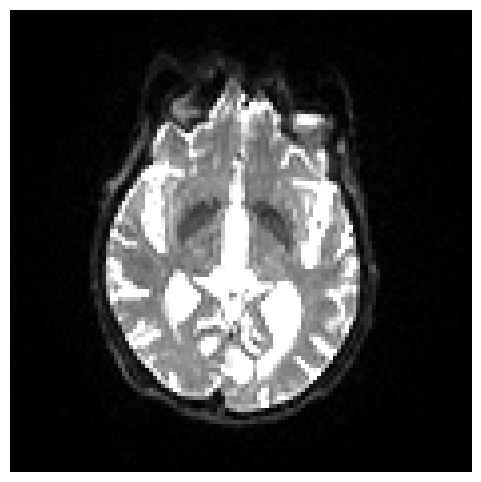

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

# Load NIfTI image
nii_path = "/home/snu/Downloads/4d_img_DTI_041_S_6192_F_88_CN (1).nii.gz"

nii_img = nib.load(nii_path)

data = nii_img.get_fdata()

print("Image shape:", data.shape)

# Take middle slice
if data.ndim == 4:
    slice_img = data[:, :, data.shape[2] // 2, 0]
else:
    slice_img = data[:, :, data.shape[2] // 2]

# Rotate for proper orientation
slice_img = np.rot90(slice_img)

# Plot
plt.figure(figsize=(6,6))
plt.imshow(slice_img, cmap="gray", interpolation="nearest")
plt.axis("off")
plt.show()

Image shape: (116, 116, 80, 55)


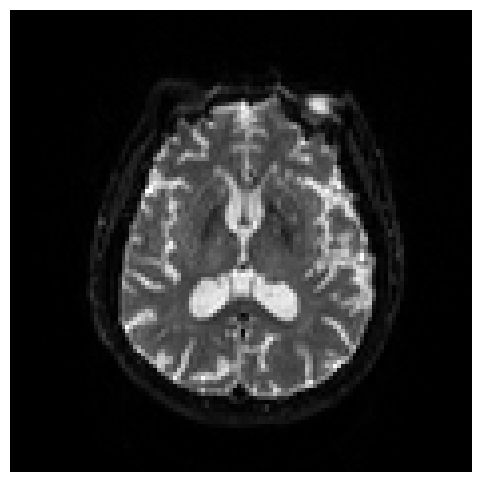

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

# Load NIfTI image
nii_path = "/home/snu/Downloads/4d_img_DTI_003_S_6833_F_87_AD.nii.gz"

nii_img = nib.load(nii_path)

data = nii_img.get_fdata()

print("Image shape:", data.shape)

# Take middle slice
if data.ndim == 4:
    slice_img = data[:, :, data.shape[2] // 2, 0]
else:
    slice_img = data[:, :, data.shape[2] // 2]

# Rotate for proper orientation
slice_img = np.rot90(slice_img)

# Plot
plt.figure(figsize=(6,6))
plt.imshow(slice_img, cmap="gray", interpolation="nearest")
plt.axis("off")
plt.show()

In [ ]:
def sim(h1, h2, tau=0.2):
    z1 = nnF.normalize(h1, dim=-1, p=2)
    z2 = nnF.normalize(h2, dim=-1, p=2)
    return torch.mm(z1, z2.t()) / tau

def contrastive_loss_wo_cross_network(h1, h2, z):
    f = lambda x: torch.exp(x)
    intra_sim = f(sim(h1, h1))
    inter_sim = f(sim(h1, h2))
    # diagonal numerator; denominator excludes intra diag
    return -torch.log(inter_sim.diag() /
                     (intra_sim.sum(dim=-1) + inter_sim.sum(dim=-1) - intra_sim.diag() + 1e-12))

def contrastive_loss_wo_cross_view(h1, h2, z):
    f = lambda x: torch.exp(x)
    cross_sim = f(sim(h1, z))
    return -torch.log(cross_sim.diag() / (cross_sim.sum(dim=-1) + 1e-12))

In [ ]:
class MLP(nn.Module):
    def __init__(self, inp_size, outp_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.PReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, outp_size)
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class ARMAEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, device, activ="SELU", num_stacks=1, num_layers=1):
        super(ARMAEncoder, self).__init__()
        self.device = device
        # Activation mapping for internal ARMA nonlinearity
        activations = {
            "SELU": nnF.selu,
            "SiLU": nnF.silu,
            "GELU": nnF.gelu,
            "ELU": nnF.elu,
            "RELU": nnF.relu
        }
        self.act = activations.get(activ, nnF.elu)

        self.arma = ARMAConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            num_stacks=num_stacks,
            num_layers=num_layers,
            act=self.act,
            shared_weights=True,
            dropout=0.25
        )
        self.batchnorm = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(0.3)
        self.mlp = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.arma(x, edge_index)
        x = self.dropout(x)
        x = self.batchnorm(x)
        logits = self.mlp(x)
        return logits

In [ ]:
class EMA():
    def __init__(self, beta):
        self.beta = beta

    def update_average(self, old, new):
        if old is None:
            return new
        return old * self.beta + (1 - self.beta) * new

def update_moving_average(ema_updater, ma_model, current_model):
    for current_params, ma_params in zip(current_model.parameters(), ma_model.parameters()):
        old_weight, up_weight = ma_params.data, current_params.data
        ma_params.data = ema_updater.update_average(old_weight, up_weight)

In [ ]:
class ARMA(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_clusters, device, activ, moving_average_decay=0.99, cut=True):
        super(ARMA, self).__init__()
        self.device = device
        self.num_clusters = num_clusters
        self.cut = cut
        # beta for mixing in contrastive combination
        self.beta = 0.6

        self.online_encoder = ARMAEncoder(input_dim, hidden_dim, device, activ)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        # freeze target encoder params
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        self.online_predictor = MLP(hidden_dim, num_clusters, hidden_dim)

        self.loss = self.cut_loss if cut else self.modularity_loss
        self.target_ema_updater = EMA(moving_average_decay)

    def reset_moving_average(self):
        del self.target_encoder
        self.target_encoder = None

    def update_ma(self):
        assert self.target_encoder is not None, 'target encoder has not been created yet'
        update_moving_average(self.target_ema_updater, self.target_encoder, self.online_encoder)

    def forward(self, data1, data2):
        # online projections
        x1 = self.online_encoder(data1)      # shape: N x hidden
        logits1 = self.online_predictor(x1)  # predictor outputs (raw)
        S1 = nnF.softmax(logits1, dim=1)

        x2 = self.online_encoder(data2)
        logits2 = self.online_predictor(x2)
        S2 = nnF.softmax(logits2, dim=1)

        # target projections (no grads)
        with torch.no_grad():
            target_proj_one = self.target_encoder(data1).detach()
            target_proj_two = self.target_encoder(data2).detach()

        # contrastive style losses
        l1 = self.beta * contrastive_loss_wo_cross_network(x1, x2, target_proj_two) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x1, x2, target_proj_two)

        l2 = self.beta * contrastive_loss_wo_cross_network(x2, x1, target_proj_one) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x2, x1, target_proj_one)

        return S1, S2, logits1, logits2, l1, l2

    def modularity_loss(self, A, S):
        C = nnF.softmax(S, dim=1)
        d = torch.sum(A, dim=1)
        m = torch.sum(A)
        B = A - torch.ger(d, d) / (2 * m + 1e-12)

        k = torch.tensor(self.num_clusters, device=self.device, dtype=torch.float32)
        n = S.shape[0]

        modularity_term = (-1.0 / (2.0 * m + 1e-12)) * torch.trace(torch.mm(torch.mm(C.t(), B), C))
        collapse_reg_term = (torch.sqrt(k) / n) * torch.norm(torch.sum(C, dim=0), p='fro') - 1.0

        return modularity_term + collapse_reg_term

    def cut_loss(self, A, S):
        S = nnF.softmax(S, dim=1)
        A_pool = torch.matmul(torch.matmul(A, S).t(), S)
        num = torch.trace(A_pool)

        D = torch.diag(torch.sum(A, dim=-1))
        D_pooled = torch.matmul(torch.matmul(D, S).t(), S)
        den = torch.trace(D_pooled)
        mincut_loss = -(num / (den + 1e-12))

        St_S = torch.matmul(S.t(), S)
        I_S = torch.eye(self.num_clusters, device=self.device)
        ortho_loss = torch.norm(St_S / (torch.norm(St_S) + 1e-12) - I_S / (torch.norm(I_S) + 1e-12))

        return mincut_loss + ortho_loss

In [ ]:
def create_adj(features, cut, alpha=1.0):
    F_norm = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-12)
    W = np.dot(F_norm, F_norm.T)

    if cut == 0:
        W = np.where(W >= alpha, 1, 0).astype(np.float32)
        if W.max() > 0:
            W = (W / W.max()).astype(np.float32)
    else:
        W = (W * (W >= alpha)).astype(np.float32)
    return W

def edge_index_from_dense(W):
    rows, cols = np.nonzero(W > 0)
    edge_index = np.vstack([rows, cols]).astype(np.int64)
    edge_weight = W[rows, cols].astype(np.float32)
    return edge_index, edge_weight

def build_adj_list(edge_index_np, num_nodes):
    adj = [[] for _ in range(num_nodes)]
    src = edge_index_np[0]
    dst = edge_index_np[1]
    for s, d in zip(src, dst):
        adj[s].append(d)
    adj = [np.array(neis, dtype=np.int64) if len(neis) > 0 else np.array([], dtype=np.int64) for neis in adj]
    return adj

def aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=None):
    rng = np.random.default_rng(seed)
    E = edge_index_np.shape[1]
    keep_mask = rng.random(E) >= drop_percent
    new_edge_index = edge_index_np[:, keep_mask]
    return new_edge_index

def aug_subgraph_edge_index(features_np, edge_index_np, adj_list, drop_percent=0.2, seed=None):
    rng = np.random.default_rng(seed)
    num_nodes = features_np.shape[0]
    s_node_num = int(num_nodes * (1 - drop_percent))
    s_node_num = max(1, s_node_num)

    center_node = int(rng.integers(0, num_nodes))
    sub_nodes = [center_node]
    front_idx = 0

    while len(sub_nodes) < s_node_num and front_idx < len(sub_nodes):
        cur = sub_nodes[front_idx]
        neighbors = adj_list[cur]
        if neighbors.size > 0:
            nbrs_shuffled = neighbors.copy()
            rng.shuffle(nbrs_shuffled)
            for nb in nbrs_shuffled:
                if nb not in sub_nodes:
                    sub_nodes.append(int(nb))
                    if len(sub_nodes) >= s_node_num:
                        break
        front_idx += 1
        if front_idx >= len(sub_nodes) and len(sub_nodes) < s_node_num:
            remaining = [n for n in range(num_nodes) if n not in sub_nodes]
            if not remaining:
                break
            add = int(rng.choice(remaining))
            sub_nodes.append(add)

    sub_nodes = sorted(set(sub_nodes))
    node_map = {old: new for new, old in enumerate(sub_nodes)}

    src = edge_index_np[0]
    dst = edge_index_np[1]
    mask_src_in = np.isin(src, sub_nodes)
    mask_dst_in = np.isin(dst, sub_nodes)
    mask = mask_src_in & mask_dst_in
    sel_src = src[mask]
    sel_dst = dst[mask]
    remapped_src = np.array([node_map[int(s)] for s in sel_src], dtype=np.int64)
    remapped_dst = np.array([node_map[int(d)] for d in sel_dst], dtype=np.int64)
    new_edge_index = np.vstack([remapped_src, remapped_dst])
    sub_features = features_np[sub_nodes, :].astype(np.float32)
    return sub_features, new_edge_index

def load_data_from_edge_index(node_feats_np, edge_index_np, device):
    node_feats = torch.from_numpy(node_feats_np).float()
    edge_index = torch.from_numpy(edge_index_np.astype(np.int64)).long()
    return node_feats, edge_index

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
hidden_dim = 256
K = 2
num_epochs = 2000
alpha = 0.5
features = X.astype(np.float32)
num_nodes = features.shape[0]
feat_dim = features.shape[1]
W0 = create_adj(features, cut=0, alpha=alpha)
edge_index_np, edge_weight_np = edge_index_from_dense(W0)
adj_list = build_adj_list(edge_index_np, num_nodes)
node_feats_all, edge_index_all = load_data_from_edge_index(features, edge_index_np, device)
data_full = Data(x=node_feats_all.to(device), edge_index=edge_index_all.to(device))
print(f"Data: {data_full}")

A1 = torch.from_numpy(W0).float().to(device)

Data: Data(x=[146, 180], edge_index=[2, 21256])



=== Fold 1 ===
Epoch 0 | Total=0.5329 | Cont=5.0294 | CE=0.7146 | Unsup=-0.2320
Epoch 500 | Total=-0.0626 | Cont=4.8352 | CE=0.3416 | Unsup=-0.4525
Epoch 1000 | Total=-0.0530 | Cont=4.7631 | CE=0.3601 | Unsup=-0.4607
Epoch 1500 | Total=-0.0803 | Cont=4.7050 | CE=0.3439 | Unsup=-0.4713
Fold 1 → Acc=0.9167 F1=0.9379 AUC=0.9634

=== Fold 2 ===
Epoch 0 | Total=0.5678 | Cont=5.0469 | CE=0.7484 | Unsup=-0.2311
Epoch 500 | Total=-0.0780 | Cont=4.6840 | CE=0.3448 | Unsup=-0.4697
Epoch 1000 | Total=-0.0855 | Cont=4.5372 | CE=0.3342 | Unsup=-0.4650
Epoch 1500 | Total=-0.1293 | Cont=4.6195 | CE=0.3078 | Unsup=-0.4833
Fold 2 → Acc=0.9318 F1=0.9486 AUC=0.9634

=== Fold 3 ===
Epoch 0 | Total=0.5481 | Cont=5.0029 | CE=0.7296 | Unsup=-0.2315
Epoch 500 | Total=-0.0781 | Cont=4.7184 | CE=0.3397 | Unsup=-0.4649
Epoch 1000 | Total=-0.1925 | Cont=4.5123 | CE=0.2331 | Unsup=-0.4708
Epoch 1500 | Total=-0.1302 | Cont=4.6666 | CE=0.2574 | Unsup=-0.4343
Fold 3 → Acc=0.9470 F1=0.9613 AUC=0.9739

=== Fold 4 ===


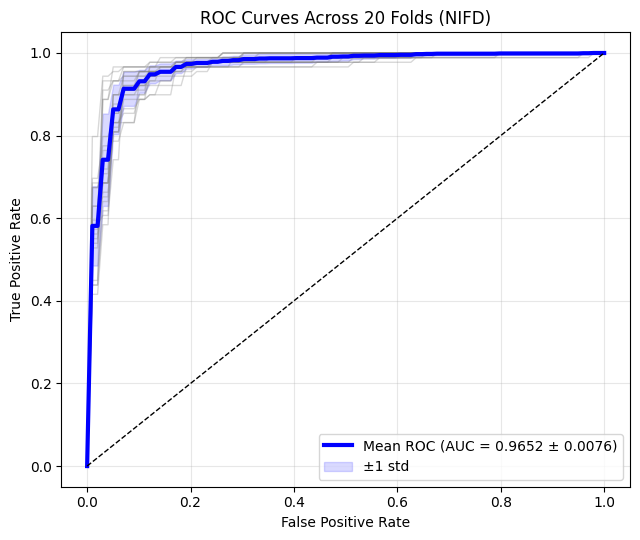

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as nnF
import torch.optim as optim
import matplotlib.pyplot as plt

from torch_geometric.data import Data
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score, roc_curve, auc
)

# -------------------------
# Metric containers
# -------------------------
accuracies, precisions, recalls, f1_scores, losses, all_auc = [], [], [], [], [], []

# For ROC
mean_fpr = np.linspace(0, 1, 100)
tprs = []
auc_per_fold = []

# -------------------------
# Cross-validation
# -------------------------
sss = StratifiedShuffleSplit(n_splits=20, test_size=0.9, random_state=SEED)

for fold, (train_idx_full, test_idx) in enumerate(sss.split(X, y)):
    print(f"\n=== Fold {fold+1} ===")

    # ---- Balanced tiny supervised set (CN vs AD) ----
    cn_idx = np.where(y == 0)[0]
    ad_idx = np.where(y == 1)[0]

    sss_class = StratifiedShuffleSplit(n_splits=20, test_size=0.2, random_state=fold)
    cn_train_idx, _ = next(sss_class.split(X[cn_idx], y[cn_idx]))
    ad_train_idx, _ = next(sss_class.split(X[ad_idx], y[ad_idx]))

    balanced_train_idx = np.concatenate([
        cn_idx[cn_train_idx],
        ad_idx[ad_train_idx]
    ])
    np.random.shuffle(balanced_train_idx)

    train_idx_t = torch.from_numpy(balanced_train_idx).long().to(device)
    test_idx_t = torch.from_numpy(test_idx).long().to(device)
    y_tensor = torch.from_numpy(y).long().to(device)

    # ---- Model ----
    model = ARMA(
        feat_dim, hidden_dim, K,
        device, activ="SELU",
        cut=True, moving_average_decay=0.99
    ).to(device)

    classifier = nn.Linear(hidden_dim, K).to(device)

    optimizer = optim.Adam(
        list(model.parameters()) + list(classifier.parameters()),
        lr=1e-4, weight_decay=1e-4
    )
    ce_loss = nn.CrossEntropyLoss()

    # -------------------------
    # Training
    # -------------------------
    for ep in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        edge_index_aug1 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep)
        edge_index_aug2 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep + 999)

        rng = np.random.default_rng(ep)
        mask = rng.random(features.shape) >= 0.2
        features_aug1 = features * mask.astype(np.float32)

        aug_feat2 = features.copy()
        drop_feat_num = int(features.size * 0.2)
        flat_idx = rng.choice(features.size, drop_feat_num, replace=False)
        rows = flat_idx // features.shape[1]
        cols = flat_idx % features.shape[1]
        aug_feat2[rows, cols] = 0.0
        features_aug2 = aug_feat2.astype(np.float32)

        node_feats1, edge_index1 = load_data_from_edge_index(features_aug1, edge_index_aug1, device)
        node_feats2, edge_index2 = load_data_from_edge_index(features_aug2, edge_index_aug2, device)

        data1 = Data(x=node_feats1.to(device), edge_index=edge_index1.to(device))
        data2 = Data(x=node_feats2.to(device), edge_index=edge_index2.to(device))

        S1, S2, logits1, logits2, l1, l2 = model(data1, data2)
        cont_loss = ((l1 + l2) / 2.0).mean()

        embeddings = model.online_encoder(data_full)
        logits_sup = classifier(embeddings[train_idx_t])
        sup_loss = ce_loss(logits_sup, y_tensor[train_idx_t])

        unsup_loss = model.loss(A1, logits1)

        loss = 0.01 * cont_loss + sup_loss + unsup_loss
        loss.backward()
        optimizer.step()
        model.update_ma()

        if ep % 500 == 0:
            print(
                f"Epoch {ep} | Total={loss.item():.4f} | "
                f"Cont={cont_loss.item():.4f} | "
                f"CE={sup_loss.item():.4f} | "
                f"Unsup={unsup_loss.item():.4f}"
            )

    # -------------------------
    # Evaluation
    # -------------------------
    model.eval()
    classifier.eval()

    with torch.no_grad():
        emb = model.online_encoder(data_full)
        logits = classifier(emb)
        probs = nnF.softmax(logits, dim=1).cpu().numpy()
        y_pred = np.argmax(probs, axis=1)

    y_test = y[test_idx]
    y_pred_test = y_pred[test_idx]
    y_proba_test = probs[test_idx, 1]

    acc = accuracy_score(y_test, y_pred_test)
    prec = precision_score(y_test, y_pred_test, zero_division=0)
    rec = recall_score(y_test, y_pred_test, zero_division=0)
    f1 = f1_score(y_test, y_pred_test, zero_division=0)

    try:
        loss_val = log_loss(y_test, y_proba_test)
    except Exception:
        loss_val = np.nan

    try:
        auc_score = roc_auc_score(y_test, y_proba_test)
    except Exception:
        auc_score = np.nan

    # ---- ROC curve for this fold ----
    try:
        fpr, tpr, _ = roc_curve(y_test, y_proba_test)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        auc_per_fold.append(auc_score)
    except Exception:
        pass

    print(f"Fold {fold+1} → Acc={acc:.4f} F1={f1:.4f} AUC={auc_score:.4f}")

    accuracies.append(acc)
    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)
    losses.append(loss_val)
    all_auc.append(auc_score)

# -------------------------
# Aggregate metrics
# -------------------------
print("\n=== Average Results ===")
print(f"Accuracy: {np.nanmean(accuracies):.4f} ± {np.nanstd(accuracies):.4f}")
print(f"Precision: {np.nanmean(precisions):.4f} ± {np.nanstd(precisions):.4f}")
print(f"Recall: {np.nanmean(recalls):.4f} ± {np.nanstd(recalls):.4f}")
print(f"F1: {np.nanmean(f1_scores):.4f} ± {np.nanstd(f1_scores):.4f}")
print(f"LogLoss: {np.nanmean(losses):.4f} ± {np.nanstd(losses):.4f}")
print(f"AUC: {np.nanmean(all_auc):.4f} ± {np.nanstd(all_auc):.4f}")

# -------------------------
# Plot ROC curves (all folds + mean)
# -------------------------
mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0)
mean_tpr[-1] = 1.0

mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.nanstd(auc_per_fold)

plt.figure(figsize=(6.5, 5.5))

# Individual folds
for i in range(len(tprs)):
    plt.plot(mean_fpr, tprs[i], color="gray", lw=1, alpha=0.3)

# Mean ROC (highlighted)
plt.plot(
    mean_fpr,
    mean_tpr,
    color="blue",
    lw=3,
    label=f"Mean ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})"
)

# Std band
plt.fill_between(
    mean_fpr,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color="blue",
    alpha=0.15,
    label="±1 std"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="black", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across 20 Folds (NIFD)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



===== COMMUNITY LEVEL ANALYSIS =====

Cluster 0 distribution: Counter({0: 28, 1: 10})
Cluster 1 distribution: Counter({1: 88, 0: 20})

ROI Comparison (Cluster 0 vs Cluster 1):

Corpus Callosum (5): Cluster0=0.5765, Cluster1=0.5361, Diff=0.0404
Fornix (7): Cluster0=0.3613, Cluster1=0.3305, Diff=0.0307
Corticospinal (8): Cluster0=0.3573, Cluster1=0.3359, Diff=0.0214
Cerebral Peduncle (16): Cluster0=0.5016, Cluster1=0.4964, Diff=0.0052
Internal Capsule (18): Cluster0=0.4403, Cluster1=0.4104, Diff=0.0299
Cingulum (36): Cluster0=0.3589, Cluster1=0.3078, Diff=0.0511
Cingulum (37): Cluster0=0.2968, Cluster1=0.2701, Diff=0.0267
Cingulum (38): Cluster0=0.2483, Cluster1=0.2448, Diff=0.0036
Cingulum (39): Cluster0=0.3203, Cluster1=0.2581, Diff=0.0623

Most Important ROIs:

Cingulum (39): 0.0623
Cingulum (36): 0.0511
Corpus Callosum (5): 0.0404
Fornix (7): 0.0307
Internal Capsule (18): 0.0299
Cingulum (37): 0.0267
Corticospinal (8): 0.0214
Cerebral Peduncle (16): 0.0052
Cingulum (38): 0.0036

Sta

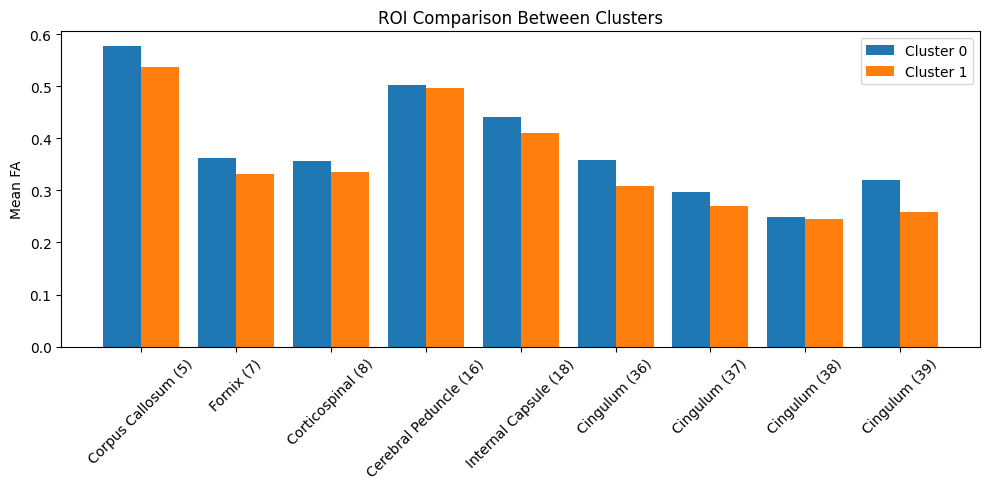

In [ ]:
from collections import Counter
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
true_labels = y

print("\n===== COMMUNITY LEVEL ANALYSIS =====\n")

cluster_labels = y_pred



for k in range(2):
    idx = (cluster_labels == k)
    print(f"Cluster {k} distribution:", Counter(true_labels[idx]))


num_rois = 9
bins_per_roi = 20

roi_names = [
    "Corpus Callosum (5)",
    "Fornix (7)",
    "Corticospinal (8)",
    "Cerebral Peduncle (16)",
    "Internal Capsule (18)",
    "Cingulum (36)",
    "Cingulum (37)",
    "Cingulum (38)",
    "Cingulum (39)",
]

roi_indices = {}
for i in range(num_rois):
    roi_indices[roi_names[i]] = (i * bins_per_roi, (i + 1) * bins_per_roi)


bin_edges = np.linspace(0, 1, bins_per_roi + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


roi_stats = {}

for roi, (start, end) in roi_indices.items():
    roi_stats[roi] = []

    for k in range(2):
        idx = (cluster_labels == k)

        roi_hist = X[idx, start:end]

        # weighted mean FA
        weighted_mean = (roi_hist * bin_centers).sum(axis=1)

        roi_stats[roi].append(weighted_mean.mean())

print("\nROI Comparison (Cluster 0 vs Cluster 1):\n")

for roi in roi_names:
    c0 = roi_stats[roi][0]
    c1 = roi_stats[roi][1]
    diff = abs(c0 - c1)

    print(f"{roi}: Cluster0={c0:.4f}, Cluster1={c1:.4f}, Diff={diff:.4f}")


roi_importance = sorted(
    [(roi, abs(vals[0] - vals[1])) for roi, vals in roi_stats.items()],
    key=lambda x: x[1],
    reverse=True
)

print("\nMost Important ROIs:\n")
for roi, diff in roi_importance:
    print(f"{roi}: {diff:.4f}")

print("\nStatistical Significance:\n")

for roi, (start, end) in roi_indices.items():

    c0_hist = X[cluster_labels == 0, start:end]
    c1_hist = X[cluster_labels == 1, start:end]

    c0_vals = (c0_hist * bin_centers).sum(axis=1)
    c1_vals = (c1_hist * bin_centers).sum(axis=1)

    stat, p = ttest_ind(c0_vals, c1_vals)

    print(f"{roi}: p-value = {p:.5f}")

roi_means_c0 = [roi_stats[roi][0] for roi in roi_names]
roi_means_c1 = [roi_stats[roi][1] for roi in roi_names]

x = np.arange(len(roi_names))

plt.figure(figsize=(10,5))
plt.bar(x - 0.2, roi_means_c0, width=0.4, label="Cluster 0")
plt.bar(x + 0.2, roi_means_c1, width=0.4, label="Cluster 1")

plt.xticks(x, roi_names, rotation=45)
plt.ylabel("Mean FA")
plt.title("ROI Comparison Between Clusters")
plt.legend()
plt.tight_layout()
plt.show()


===== FULL ROI DISTRIBUTION BOXPLOT =====



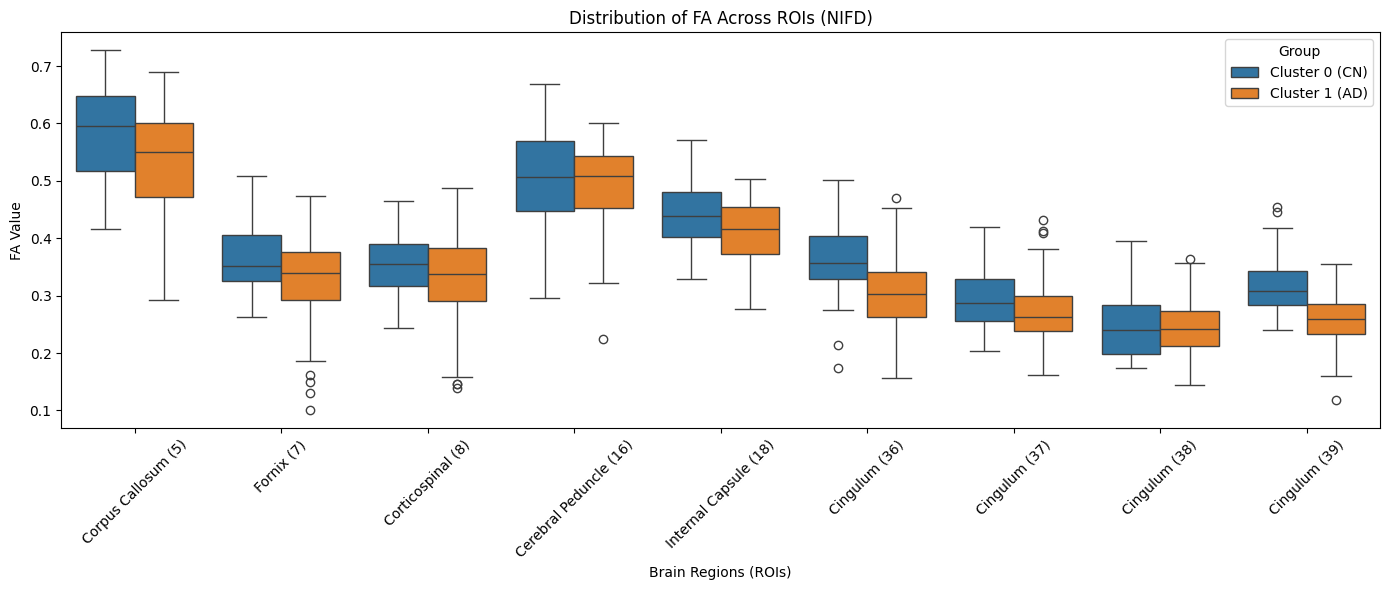

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

print("\n===== FULL ROI DISTRIBUTION BOXPLOT =====\n")

data_list = []

# loop through ALL ROIs
for roi in roi_names:
    start, end = roi_indices[roi]

    # extract histograms
    c0_hist = X[cluster_labels == 0, start:end]
    c1_hist = X[cluster_labels == 1, start:end]

    # convert histogram → FA values
    c0_vals = (c0_hist * bin_centers).sum(axis=1)
    c1_vals = (c1_hist * bin_centers).sum(axis=1)

    # store data
    for val in c0_vals:
        data_list.append([roi, val, "Cluster 0 (CN)"])

    for val in c1_vals:
        data_list.append([roi, val, "Cluster 1 (AD)"])

# create dataframe
df = pd.DataFrame(data_list, columns=["ROI", "FA", "Group"])

# plot
plt.figure(figsize=(14,6))
sns.boxplot(x="ROI", y="FA", hue="Group", data=df)

plt.xticks(rotation=45)
plt.title("Distribution of FA Across ROIs )")
plt.ylabel("FA Value")
plt.xlabel("Brain Regions (ROIs)")
plt.tight_layout()
plt.show()

In [ ]:
# Find nodes connected to both clusters
bridge_nodes = []

for i in range(num_nodes):
    neighbors = adj_list[i]
    if len(neighbors) == 0:
        continue

    neighbor_clusters = set(cluster_labels[neighbors])

    if len(neighbor_clusters) > 1:
        bridge_nodes.append(i)

print("Number of bridge nodes:", len(bridge_nodes))

Number of bridge nodes: 146


In [ ]:
bridge_fa = X[bridge_nodes]

mean_bridge = bridge_fa.mean(axis=0)
mean_c0 = X[cluster_labels == 0].mean(axis=0)
mean_c1 = X[cluster_labels == 1].mean(axis=0)

print("Bridge closer to:",
      "Controls" if np.linalg.norm(mean_bridge - mean_c0) < np.linalg.norm(mean_bridge - mean_c1) else "Patients")

Bridge closer to: Patients


In [ ]:
print("\n===== GROUND TRUTH ROI ANALYSIS (CN vs MCI) =====\n")

roi_stats_gt = {}

for roi, (start, end) in roi_indices.items():

    cn_hist = X[y == 0, start:end]
    mci_hist = X[y == 1, start:end]

    cn_vals = (cn_hist * bin_centers).sum(axis=1)
    mci_vals = (mci_hist * bin_centers).sum(axis=1)

    mean_cn = cn_vals.mean()
    mean_mci = mci_vals.mean()

    diff = abs(mean_cn - mean_mci)

    roi_stats_gt[roi] = (mean_cn, mean_mci, diff)

    print(f"{roi}: CN={mean_cn:.4f}, MCI={mean_mci:.4f}, Diff={diff:.4f}")


===== GROUND TRUTH ROI ANALYSIS (CN vs MCI) =====

Corpus Callosum (5): CN=0.5702, MCI=0.5350, Diff=0.0352
Fornix (7): CN=0.3609, MCI=0.3276, Diff=0.0334
Corticospinal (8): CN=0.3575, MCI=0.3336, Diff=0.0239
Cerebral Peduncle (16): CN=0.4954, MCI=0.4989, Diff=0.0035
Internal Capsule (18): CN=0.4407, MCI=0.4071, Diff=0.0336
Cingulum (36): CN=0.3593, MCI=0.3024, Diff=0.0569
Cingulum (37): CN=0.2816, MCI=0.2748, Diff=0.0068
Cingulum (38): CN=0.2469, MCI=0.2451, Diff=0.0018
Cingulum (39): CN=0.3096, MCI=0.2570, Diff=0.0526


In [ ]:
roi_importance_gt = sorted(
    [(roi, vals[2]) for roi, vals in roi_stats_gt.items()],
    key=lambda x: x[1],
    reverse=True
)

print("\nMost Important ROIs (Ground Truth):\n")
for roi, diff in roi_importance_gt:
    print(f"{roi}: {diff:.4f}")


Most Important ROIs (Ground Truth):

Cingulum (36): 0.0569
Cingulum (39): 0.0526
Corpus Callosum (5): 0.0352
Internal Capsule (18): 0.0336
Fornix (7): 0.0334
Corticospinal (8): 0.0239
Cingulum (37): 0.0068
Cerebral Peduncle (16): 0.0035
Cingulum (38): 0.0018


Saved: /content/drive/MyDrive/TejaswiAbburi_va797/Dataset/nifti_images/CN_mid_slice.png
Saved: /content/drive/MyDrive/TejaswiAbburi_va797/Dataset/nifti_images/MCI_mid_slice.png
Saved: /content/drive/MyDrive/TejaswiAbburi_va797/Dataset/nifti_images/AD_mid_slice.png


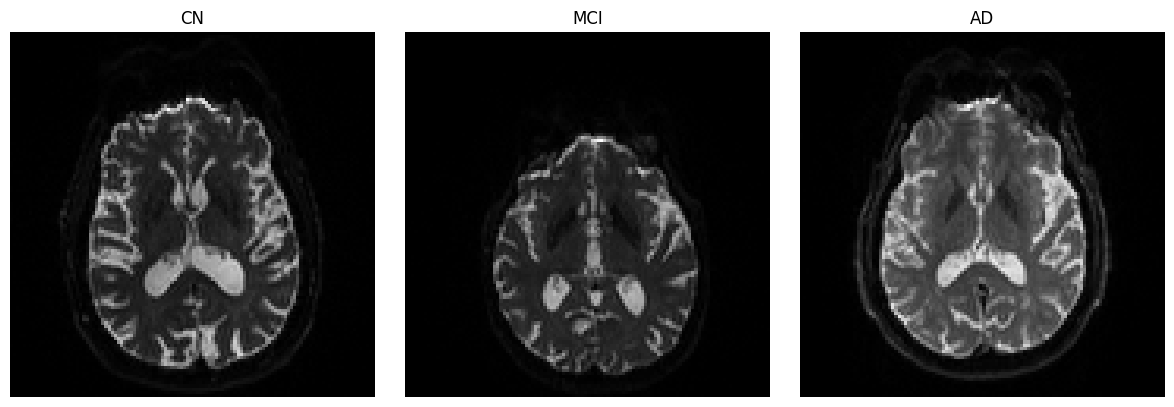

In [ ]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

paths = [
    "/content/drive/MyDrive/TejaswiAbburi_va797/Dataset/ISBI_ADNI_CN_dataset/Ordered_4d_all_CN/all_55_diff_4d_img_ordered_CN/4d_img_DTI_016_S_6381_M_73_CN.nii.gz",
    "/content/drive/MyDrive/TejaswiAbburi_va797/Dataset/ISBI_ADNI_MCI_dataset/Ordered_4d_all_MCI/all_55_diff_4d_img_ordered_MCI/4d_img_DTI_016_S_6926_F_81_MCI.nii.gz",
    "/content/drive/MyDrive/TejaswiAbburi_va797/Dataset/ISBI_ADNI_AD_dataset/Ordered_4d_all_AD/all_55_diff_4d_img_ordered_AD/4d_img_DTI_003_S_6264_M_55_AD.nii.gz"
]

labels = ["CN", "MCI", "AD"]

# Output directory to save images
output_dir = "/content/drive/MyDrive/TejaswiAbburi_va797/Dataset/nifti_images"
os.makedirs(output_dir, exist_ok=True)

plt.figure(figsize=(12, 4))

for i, (path, label) in enumerate(zip(paths, labels)):

    if not os.path.exists(path):
        print(f"File not found, skipping: {path}")
        continue

    # Load NIfTI file
    img = nib.load(path)
    data = img.get_fdata()

    # If 4D DTI, take the first volume
    if data.ndim == 4:
        data = data[..., 0]

    # Take middle axial slice
    mid_slice = data.shape[2] // 2
    slice_img = data[:, :, mid_slice].T

    # Plot
    plt.subplot(1, 3, i + 1)
    plt.imshow(slice_img, cmap="gray", origin="lower")
    plt.title(label)
    plt.axis("off")

    # Save image
    save_path = os.path.join(output_dir, f"{label}_mid_slice.png")
    plt.imsave(save_path, slice_img, cmap="gray")
    print(f"Saved: {save_path}")

plt.tight_layout()
plt.show()


In [ ]:
ls /home/snu/Downloads/4d_img_DTI_016_S_6839_F_70_AD_nii.gz


ls: cannot access '/home/snu/Downloads/4d_img_DTI_016_S_6839_F_70_AD_nii.gz': No such file or directory


In [2]:
# -*- coding: utf-8 -*-
"""
ARMA-C3 Ablation Study on NIFD (Controls vs Patients)
Ablation over:
  1. activation function  (activ)
  2. graph threshold      (alpha)
  3. contrastive weight   (lambda_con)
  4. structural weight    (lambda_struct)
Same 20-fold protocol as the main ARMA-C3 NIFD code.
"""

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as nnF
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import ARMAConv
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score,
)

# ============================================================
# Reproducibility
# ============================================================
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ============================================================
# Load NIFD Controls / Patients FA histogram features (local paths)
# ============================================================
controls_path = "/home/snu/Downloads/NIFD_Control_FA_Histogram_Feature.npy"
patients_path = "/home/snu/Downloads/NIFD_Patients_FA_Histogram_Feature.npy"

Controls_FA_array = np.load(controls_path, allow_pickle=True)
Patients_FA_array = np.load(patients_path, allow_pickle=True)

print("Controls Shape:", Controls_FA_array.shape)
print("Patients Shape:", Patients_FA_array.shape)

X = np.vstack([Controls_FA_array, Patients_FA_array])
y = np.hstack([
    np.zeros(Controls_FA_array.shape[0], dtype=np.int64),  # 0 = Control
    np.ones (Patients_FA_array.shape[0], dtype=np.int64),  # 1 = Patient
])

perm = np.random.permutation(X.shape[0])
X = X[perm]
y = y[perm]
features = X.astype(np.float32)
num_nodes, feat_dim = features.shape
print(f"Features: {features.shape}, Labels: {y.shape}")

# ============================================================
# Building blocks (identical to main ARMA-C3 code)
# ============================================================
def sim(h1, h2, tau=0.2):
    z1 = nnF.normalize(h1, dim=-1, p=2)
    z2 = nnF.normalize(h2, dim=-1, p=2)
    return torch.mm(z1, z2.t()) / tau


def contrastive_loss_wo_cross_network(h1, h2, z, tau):
    f = lambda x: torch.exp(x)
    intra_sim = f(sim(h1, h1, tau))
    inter_sim = f(sim(h1, h2, tau))
    return -torch.log(inter_sim.diag() /
                      (intra_sim.sum(dim=-1) + inter_sim.sum(dim=-1) - intra_sim.diag() + 1e-12))


def contrastive_loss_wo_cross_view(h1, h2, z, tau):
    f = lambda x: torch.exp(x)
    cross_sim = f(sim(h1, z, tau))
    return -torch.log(cross_sim.diag() / (cross_sim.sum(dim=-1) + 1e-12))


class MLP(nn.Module):
    def __init__(self, inp_size, outp_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.PReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, outp_size),
        )
    def forward(self, x):
        return self.net(x)


class ARMAEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, device, activ="SELU",
                 num_stacks=1, num_layers=1):
        super().__init__()
        self.device = device
        activations = {
            "SELU": nnF.selu,
            "SiLU": nnF.silu,
            "GELU": nnF.gelu,
            "ELU":  nnF.elu,
            "RELU": nnF.relu,
        }
        self.act = activations.get(activ, nnF.elu)
        self.arma = ARMAConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            num_stacks=num_stacks,
            num_layers=num_layers,
            act=self.act,
            shared_weights=True,
            dropout=0.25,
        )
        self.batchnorm = nn.BatchNorm1d(hidden_dim)
        self.dropout   = nn.Dropout(0.3)
        self.mlp       = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.arma(x, edge_index)
        x = self.dropout(x)
        x = self.batchnorm(x)
        return self.mlp(x)


class EMA():
    def __init__(self, beta):
        self.beta = beta
    def update_average(self, old, new):
        if old is None:
            return new
        return old * self.beta + (1 - self.beta) * new


def update_moving_average(ema_updater, ma_model, current_model):
    for current_params, ma_params in zip(current_model.parameters(), ma_model.parameters()):
        old_weight, up_weight = ma_params.data, current_params.data
        ma_params.data = ema_updater.update_average(old_weight, up_weight)


class ARMA(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_clusters, device,
                 activ, moving_average_decay=0.99, cut=False, tau=0.2, beta=0.6):
        super().__init__()
        self.device       = device
        self.num_clusters = num_clusters
        self.cut          = cut
        self.beta         = beta
        self.tau          = tau

        self.online_encoder = ARMAEncoder(input_dim, hidden_dim, device, activ)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        self.online_predictor = MLP(hidden_dim, num_clusters, hidden_dim)
        self.loss = self.cut_loss if cut else self.modularity_loss
        self.target_ema_updater = EMA(moving_average_decay)

    def update_ma(self):
        update_moving_average(self.target_ema_updater, self.target_encoder, self.online_encoder)

    def forward(self, data1, data2):
        x1 = self.online_encoder(data1)
        logits1 = self.online_predictor(x1)
        S1 = nnF.softmax(logits1, dim=1)

        x2 = self.online_encoder(data2)
        logits2 = self.online_predictor(x2)
        S2 = nnF.softmax(logits2, dim=1)

        with torch.no_grad():
            target_proj_one = self.target_encoder(data1).detach()
            target_proj_two = self.target_encoder(data2).detach()

        l1 = self.beta * contrastive_loss_wo_cross_network(x1, x2, target_proj_two, self.tau) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x1, x2, target_proj_two, self.tau)
        l2 = self.beta * contrastive_loss_wo_cross_network(x2, x1, target_proj_one, self.tau) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x2, x1, target_proj_one, self.tau)
        return S1, S2, logits1, logits2, l1, l2

    def modularity_loss(self, A, S):
        C = nnF.softmax(S, dim=1)
        d = torch.sum(A, dim=1)
        m = torch.sum(A)
        B = A - torch.ger(d, d) / (2 * m + 1e-12)
        k = torch.tensor(self.num_clusters, device=self.device, dtype=torch.float32)
        n = S.shape[0]
        modularity_term   = (-1.0 / (2.0 * m + 1e-12)) * torch.trace(torch.mm(torch.mm(C.t(), B), C))
        collapse_reg_term = (torch.sqrt(k) / n) * torch.norm(torch.sum(C, dim=0), p='fro') - 1.0
        return modularity_term + collapse_reg_term

    def cut_loss(self, A, S):
        S = nnF.softmax(S, dim=1)
        A_pool = torch.matmul(torch.matmul(A, S).t(), S)
        num = torch.trace(A_pool)
        D = torch.diag(torch.sum(A, dim=-1))
        D_pooled = torch.matmul(torch.matmul(D, S).t(), S)
        den = torch.trace(D_pooled)
        mincut_loss = -(num / (den + 1e-12))
        St_S = torch.matmul(S.t(), S)
        I_S  = torch.eye(self.num_clusters, device=self.device)
        ortho_loss = torch.norm(St_S / (torch.norm(St_S) + 1e-12) - I_S / (torch.norm(I_S) + 1e-12))
        return mincut_loss + ortho_loss


def create_adj(features, cut, alpha=1.0):
    F_norm = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-12)
    W = np.dot(F_norm, F_norm.T)
    if cut == 0:
        W = np.where(W >= alpha, 1, 0).astype(np.float32)
        if W.max() > 0:
            W = (W / W.max()).astype(np.float32)
    else:
        W = (W * (W >= alpha)).astype(np.float32)
    return W


def edge_index_from_dense(W):
    rows, cols = np.nonzero(W > 0)
    return np.vstack([rows, cols]).astype(np.int64)


def aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=None):
    rng = np.random.default_rng(seed)
    E = edge_index_np.shape[1]
    keep_mask = rng.random(E) >= drop_percent
    return edge_index_np[:, keep_mask]


def load_data_from_edge_index(node_feats_np, edge_index_np, device):
    node_feats = torch.from_numpy(node_feats_np).float()
    edge_index = torch.from_numpy(edge_index_np.astype(np.int64)).long()
    return node_feats, edge_index


# ============================================================
# Single 20-fold experiment
# ============================================================
def run_experiment(activ, alpha, lambda_con, lambda_struct,
                   hidden_dim=256, K=2, num_epochs=2000,
                   lr=1e-4, weight_decay=1e-4,
                   tau=0.2, beta=0.6, moving_average_decay=0.99,
                   n_splits=20, test_size=0.9, inner_test_size=0.9,
                   verbose=False):
    """
    Runs 20-fold CV for the given NIFD hyperparameter config.
    """
    # Build graph for this alpha
    W0 = create_adj(features, cut=0, alpha=alpha)
    edge_index_np = edge_index_from_dense(W0)
    node_feats_all, edge_index_all = load_data_from_edge_index(features, edge_index_np, device)
    data_full = Data(x=node_feats_all.to(device), edge_index=edge_index_all.to(device))
    A1 = torch.from_numpy(W0).float().to(device)

    accuracies, precisions, recalls, f1_scores, losses, all_auc = [], [], [], [], [], []

    sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=SEED)

    for fold, (train_idx_full, test_idx) in enumerate(sss.split(X, y)):
        control_idx = np.where(y == 0)[0]
        patient_idx = np.where(y == 1)[0]

        sss_class = StratifiedShuffleSplit(n_splits=20, test_size=inner_test_size, random_state=fold)
        control_train_idx, _ = next(sss_class.split(X[control_idx], y[control_idx]))
        patient_train_idx, _ = next(sss_class.split(X[patient_idx], y[patient_idx]))

        balanced_train_idx = np.concatenate([
            control_idx[control_train_idx],
            patient_idx[patient_train_idx],
        ])
        np.random.shuffle(balanced_train_idx)

        train_idx_t = torch.from_numpy(balanced_train_idx).long().to(device)
        y_tensor    = torch.from_numpy(y).long().to(device)

        # Per-fold seeding for reproducibility
        torch.manual_seed(SEED + fold)
        np.random.seed(SEED + fold)

        model = ARMA(
            feat_dim, hidden_dim, K, device,
            activ=activ, cut=False,     # modularity-based structural regularization
            moving_average_decay=moving_average_decay,
            tau=tau, beta=beta,
        ).to(device)

        classifier = nn.Linear(hidden_dim, K).to(device)
        optimizer = optim.Adam(
            list(model.parameters()) + list(classifier.parameters()),
            lr=lr, weight_decay=weight_decay,
        )
        ce_loss = nn.CrossEntropyLoss()

        for ep in range(num_epochs):
            model.train()
            optimizer.zero_grad()

            edge_index_aug1 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep)
            edge_index_aug2 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep + 999)

            rng = np.random.default_rng(ep)
            mask = rng.random(features.shape) >= 0.2
            features_aug1 = features * mask.astype(np.float32)

            aug_feat2 = features.copy()
            drop_feat_num = int(features.size * 0.2)
            flat_idx = rng.choice(features.size, drop_feat_num, replace=False)
            rows = flat_idx // features.shape[1]
            cols = flat_idx %  features.shape[1]
            aug_feat2[rows, cols] = 0.0
            features_aug2 = aug_feat2.astype(np.float32)

            node_feats1, edge_index1 = load_data_from_edge_index(features_aug1, edge_index_aug1, device)
            node_feats2, edge_index2 = load_data_from_edge_index(features_aug2, edge_index_aug2, device)

            data1 = Data(x=node_feats1.to(device), edge_index=edge_index1.to(device))
            data2 = Data(x=node_feats2.to(device), edge_index=edge_index2.to(device))

            S1, S2, logits1, logits2, l1, l2 = model(data1, data2)
            cont_loss = ((l1 + l2) / 2.0).mean()

            embeddings = model.online_encoder(data_full)
            logits_sup = classifier(embeddings[train_idx_t])
            sup_loss   = ce_loss(logits_sup, y_tensor[train_idx_t])

            struct_loss = model.loss(A1, logits1)

            loss = sup_loss + lambda_con * cont_loss + lambda_struct * struct_loss
            loss.backward()
            optimizer.step()
            model.update_ma()

        # Evaluation
        model.eval()
        classifier.eval()
        with torch.no_grad():
            emb    = model.online_encoder(data_full)
            logits = classifier(emb)
            probs  = nnF.softmax(logits, dim=1).cpu().numpy()
            y_pred = np.argmax(probs, axis=1)

        y_test       = y[test_idx]
        y_pred_test  = y_pred[test_idx]
        y_proba_test = probs[test_idx, 1]

        acc  = accuracy_score(y_test, y_pred_test)
        prec = precision_score(y_test, y_pred_test, zero_division=0)
        rec  = recall_score(y_test, y_pred_test, zero_division=0)
        f1   = f1_score(y_test, y_pred_test, zero_division=0)
        try:    lv = log_loss(y_test, y_proba_test)
        except: lv = np.nan
        try:    auc_sc = roc_auc_score(y_test, y_proba_test)
        except: auc_sc = np.nan

        accuracies.append(acc);  precisions.append(prec)
        recalls.append(rec);     f1_scores.append(f1)
        losses.append(lv);       all_auc.append(auc_sc)

        if verbose:
            print(f"     Fold {fold+1}: Acc={acc:.4f} F1={f1:.4f} AUC={auc_sc:.4f}")

    return {
        "Accuracy":     float(np.nanmean(accuracies)),
        "Accuracy_std": float(np.nanstd(accuracies)),
        "Precision":    float(np.nanmean(precisions)),
        "Recall":       float(np.nanmean(recalls)),
        "F1":           float(np.nanmean(f1_scores)),
        "LogLoss":      float(np.nanmean(losses)),
        "AUC":          float(np.nanmean(all_auc)),
        "AUC_std":      float(np.nanstd(all_auc)),
    }


# ============================================================
# Ablation configuration (NIFD reference values from Table 1)
# ============================================================
# Table 1 row for NIFD:
#   Act = SELU, α = 0.83, τ = 0.50, β = 0.50,
#   EMA = 0.70, λ_con = 1e-2, λ_struct = 2.0,
#   LR = 1e-4, WD = 1e-4, Epochs = 2000
#
# NOTE: To match the paper's NIFD config exactly, also set
#   tau=0.50, beta=0.50, moving_average_decay=0.70
# inside run_experiment(...) when calling.
DEFAULTS = dict(
    activ="SELU",
    alpha=0.83,
    lambda_con=1e-2,
    lambda_struct=2.0,
)

ABLATIONS = {
    "activation":    ["RELU", "ELU", "SELU", "GELU"],
    "alpha":         [0.60, 0.75, 0.83, 0.92],
    "lambda_con":    [0.0, 1e-4, 1e-3, 1e-2],
    "lambda_struct": [0.0, 0.5, 1.0, 2.0],
}

# Run one group at a time if time-constrained:
# e.g. RUN = ["activation"], then RUN = ["alpha"], etc.
RUN = ["activation", "alpha", "lambda_con", "lambda_struct"]

all_results = {}

for abl_name in RUN:
    print(f"\n{'='*70}")
    print(f"ABLATION (NIFD): {abl_name}")
    print(f"{'='*70}")
    all_results[abl_name] = {}

    for value in ABLATIONS[abl_name]:
        cfg = DEFAULTS.copy()
        cfg[abl_name] = value

        print(f"\n>>> {abl_name} = {value}  (others fixed at NIFD default)")

        res = run_experiment(
            activ=cfg["activ"],
            alpha=cfg["alpha"],
            lambda_con=cfg["lambda_con"],
            lambda_struct=cfg["lambda_struct"],
            # If you want the exact Table-1 NIFD config, uncomment:
            # tau=0.50, beta=0.50, moving_average_decay=0.70,
        )
        all_results[abl_name][value] = res
        print(f"    Acc={res['Accuracy']:.4f}  F1={res['F1']:.4f}  AUC={res['AUC']:.4f}")

# ============================================================
# Summary tables
# ============================================================
print("\n\n" + "="*70)
print("ABLATION SUMMARY (NIFD Controls vs Patients, 20-fold)")
print("="*70)

for abl_name, results in all_results.items():
    print(f"\n{abl_name}")
    print(f"  {'Value':<12} {'Accuracy':<12} {'F1':<12} {'AUC':<12}")
    print(f"  {'-'*48}")
    for val, res in results.items():
        print(f"  {str(val):<12} {res['Accuracy']:.4f}      {res['F1']:.4f}      {res['AUC']:.4f}")

    # Sensitivity (max − min over the tested grid) for the rebuttal
    accs = [r["Accuracy"] for r in results.values()]
    f1s  = [r["F1"]       for r in results.values()]
    aucs = [r["AUC"]      for r in results.values()]
    print(f"  Spread (max − min):  Acc={max(accs)-min(accs):.4f}  "
          f"F1={max(f1s)-min(f1s):.4f}  AUC={max(aucs)-min(aucs):.4f}")

Device: cuda
Controls Shape: (48, 180)
Patients Shape: (98, 180)
Features: (146, 180), Labels: (146,)

ABLATION (NIFD): activation

>>> activation = RELU  (others fixed at NIFD default)
    Acc=0.7011  F1=0.7623  AUC=0.7649

>>> activation = ELU  (others fixed at NIFD default)
    Acc=0.7008  F1=0.7619  AUC=0.7649

>>> activation = SELU  (others fixed at NIFD default)
    Acc=0.7004  F1=0.7617  AUC=0.7649

>>> activation = GELU  (others fixed at NIFD default)
    Acc=0.7008  F1=0.7619  AUC=0.7649

ABLATION (NIFD): alpha

>>> alpha = 0.6  (others fixed at NIFD default)
    Acc=0.7167  F1=0.7845  AUC=0.7727

>>> alpha = 0.75  (others fixed at NIFD default)
    Acc=0.7019  F1=0.7664  AUC=0.7652

>>> alpha = 0.83  (others fixed at NIFD default)
    Acc=0.7008  F1=0.7619  AUC=0.7649

>>> alpha = 0.92  (others fixed at NIFD default)
    Acc=0.6758  F1=0.7324  AUC=0.7558

ABLATION (NIFD): lambda_con

>>> lambda_con = 0.0  (others fixed at NIFD default)
    Acc=0.7015  F1=0.7630  AUC=0.7644

>

# Task
Define the `SEED` variable, then update the training loop to rename `cn_idx` to `control_idx` and `mci_idx` to `patient_idx`, and finally execute the training and evaluation to summarize the model's performance using the 'Control' and 'Patient' labels.

## Define SEED and Rename Indices

### Subtask:
Define the `SEED` variable and rename `cn_idx` to `control_idx` and `mci_idx` to `patient_idx` in the training loop to match 'Control' and 'Patient' terminology, improving code clarity and resolving the `NameError`.


**Reasoning**:
The first instruction is to define the `SEED` variable in a new code cell. This will resolve the `NameError` in cell `unLiGhaXn39r` and set a consistent random seed for reproducibility.

